In [4]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_core.messages import BaseMessage, HumanMessage
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

load_dotenv()
model = ChatOpenAI(model="gpt-5.6-luna")


In [5]:
# 상태: 노드들이 공유하는 대화 메시지와 메시지 병합 규칙을 정의합니다.
class State(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]


# 노드: 현재 대화를 모델에 전달하고 응답을 상태 업데이트로 반환합니다.
def generate(state: State):
    return {"messages": [model.invoke(state["messages"])]}


graph_builder = StateGraph(State)
graph_builder.add_node("generate", generate)

# 엣지: START → generate → END 순서로 실행합니다.
graph_builder.add_edge(START, "generate")
graph_builder.add_edge("generate", END)

In [6]:
# graph = graph_builder.compile()

# 메모리 o 그래프 정의
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()
config = {"configurable": {"thread_id": "abcd"}}

graph = graph_builder.compile(checkpointer=memory)

In [9]:
# 노트북 입력창에서 대화합니다. 종료하려면 exit, quit, q를 입력하세요.
while True:
    user_input = input("You\t: ")

    if user_input.strip().lower() in {"exit", "quit", "q"}:
        break

    if not user_input.strip():
        continue

    final_state = None
    for event in graph.stream(
        {"messages": [HumanMessage(content=user_input)]},
        config=config, # 메모리 o 추가
        stream_mode="values",
    ):
        event["messages"][-1].pretty_print()
        final_state = event

    if final_state is not None:
        print(f'\n현재 메시지 갯수: {len(final_state["messages"])}\n-------------------\n')


================================ Human Message =================================

내 이름이 뭐지?
================================== Ai Message ==================================

네 이름은 **뚱이**야! 😄⭐

현재 메시지 갯수: 14
-------------------



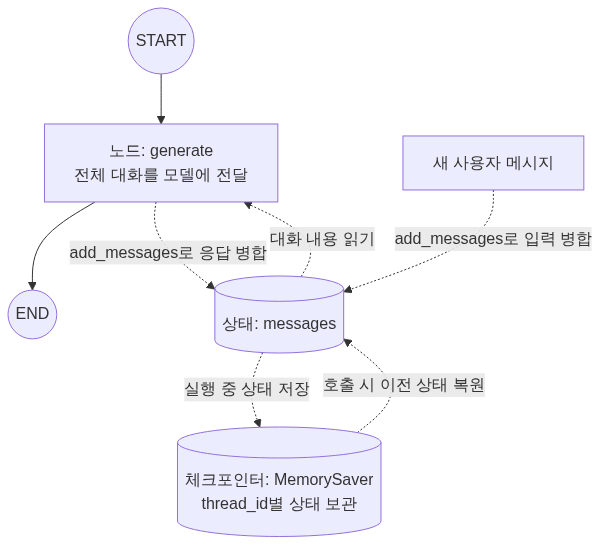

In [10]:
from IPython.display import Image, display
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

mermaid_code = """
flowchart TD
    START((START)) --> GENERATE["노드: generate<br/>전체 대화를 모델에 전달"]
    GENERATE --> END((END))

    STATE[("상태: messages")]
    MEMORY[("체크포인터: MemorySaver<br/>thread_id별 상태 보관")]
    INPUT["새 사용자 메시지"]

    MEMORY -.->|"호출 시 이전 상태 복원"| STATE
    INPUT -.->|"add_messages로 입력 병합"| STATE
    STATE -.->|"대화 내용 읽기"| GENERATE
    GENERATE -.->|"add_messages로 응답 병합"| STATE
    STATE -.->|"실행 중 상태 저장"| MEMORY
"""

display(Image(data=draw_mermaid_png(mermaid_code)))

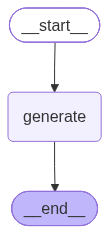

In [11]:
display(Image(data=graph.get_graph().draw_mermaid_png()))

### 메모리로 대화를 이어가는 LangGraph

- **상태(State)**: `messages`에 대화 내용을 저장한다. `add_messages`는 새 사용자 메시지와 모델 응답을 기존 대화에 병합한다.
- **노드(Node)**: `generate`가 상태의 전체 대화를 모델에 전달하고 응답을 반환한다.
- **엣지(Edge)**: `START → generate → END` 순서로 실행한다.
- **체크포인터(MemorySaver)**: 실행 중의 상태를 메모리에 저장하고, 다음 호출에서 복원한다.
- **대화 식별자(thread_id)**: 같은 ID로 호출하면 이전 대화를 이어가고, 다른 ID로 호출하면 별도 대화를 시작한다.

**작업 흐름**: 이전 상태 복원 → 새 사용자 메시지 병합 → 모델 응답 생성 → 응답 병합 및 상태 저장

`q`는 입력 반복문만 종료한다. 대화 입력 셀을 다시 실행해도 같은 메모리 객체와 `thread_id`를 사용하면 메시지가 계속 누적된다.

새 대화는 `thread_id`를 변경해 시작한다. 전체 메모리는 `MemorySaver`를 새로 만들고 그래프를 다시 컴파일하거나, 커널을 재시작하면 초기화된다.